# LO2v2 metrics exploration

Run the downloader and evaluator from the repository root first. Each training or test fold uses separate collection runs. The normal label is `correct`. Error labels identify client API test scenarios.

In [16]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
features = pd.read_parquet(root / "data/processed/scenario_features.parquet")
predictions = pd.read_csv(root / "results/predictions.csv")
metrics = json.loads((root / "results/metrics.json").read_text())
metrics

{'files': 70,
 'input_bytes': 170510605,
 'runs': 10,
 'scenario_windows': 540,
 'scenarios': 54,
 'error_prevalence': 0.9814814814814815,
 'roc_auc': 0.619056603773585,
 'average_precision': 0.9879801559491741,
 'scenario_top1': 0.033962264150943396,
 'scenario_top3': 0.0830188679245283,
 'scenario_balanced_accuracy': 0.0339622641509434,
 'preprocessing_median_seconds': {'1': 14.88, '2': 11.586}}

In [17]:
inventory = predictions.groupby(["run", "error"]).size().unstack(fill_value=0)
inventory.columns = ["Correct", "API error"]
display(inventory)
missing = features.drop(columns=["run", "test", "service"]).isna().mean()
display(missing.rename("Missing fraction").to_frame())

,Correct,API error
run,,
LO2_run_1738661358,1,53
LO2_run_1739484002,1,53
LO2_run_1739613601,1,53
LO2_run_1739754001,1,53
LO2_run_1739894401,1,53
LO2_run_1740024001,1,53
LO2_run_1740164402,1,53
LO2_run_1740304801,1,53
LO2_run_1740434401,1,53


,Missing fraction
container_memory_rss,0.0
container_memory_working_set_bytes,0.0
container_cpu_usage_seconds_total,0.0
container_fs_reads_bytes_total,0.0
container_fs_writes_bytes_total,0.0
container_network_receive_bytes_total,0.0
container_network_transmit_bytes_total,0.0


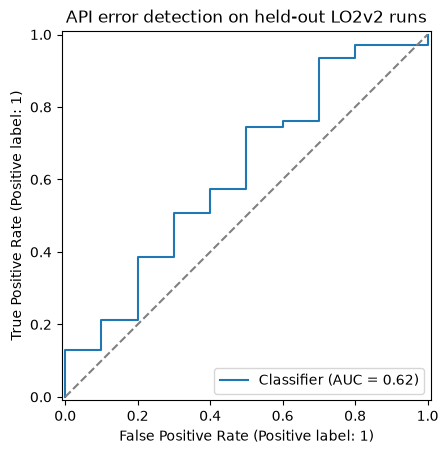

In [18]:
RocCurveDisplay.from_predictions(predictions["error"], predictions["score"])
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("API error detection on held-out LO2v2 runs")
plt.show()